# Learning Curves Diagnostics

*Companion to* **Mastering CatBoost — Pro Edition**, Chapter 4: Tuning & Diagnostics as System Control, §4.5 (Diagnostics: Reading the Heartbeat).

Once early stopping is engaged, "your role shifts from pilot to doctor": the training and validation curves are the patient's vitals. This lab manufactures the three classic pathologies — the Divergence (overfitting), the Plateau (underfitting), and the Spike (instability) — on one dataset so you can recognize each shape instantly, then uses staged predictions and `shrink()` to act on the diagnosis.

In [2]:
# %pip install -q catboost==1.2.10 scikit-learn==1.6.1 numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0

import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier, Pool

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

In [3]:
from sklearn.datasets import make_classification
from sklearn.metrics import roc_auc_score, log_loss
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=10_000, n_features=25, n_informative=10,
                           n_redundant=5, flip_y=0.12, random_state=RANDOM_SEED)
X = X.astype(np.float32)
X_tr, X_rest, y_tr, y_rest = train_test_split(X, y, test_size=0.4, random_state=RANDOM_SEED, stratify=y)
X_va, X_te, y_va, y_te = train_test_split(X_rest, y_rest, test_size=0.5, random_state=RANDOM_SEED, stratify=y_rest)
print(f"train {X_tr.shape} | valid {X_va.shape} | test {X_te.shape}")

train (6000, 25) | valid (2000, 25) | test (2000, 25)


## 1. Stress-testing four configurations (§4.5.1)

Same data, three deliberately extreme configurations plus a balanced reference. We record Logloss and AUC. The labels below are **hypotheses to check**: a finite run may not reproduce the named silhouette.

| Candidate | Settings | Diagnostic hypothesis |
|---|---|---|
| high capacity | `depth=10, l2_leaf_reg=0.2, learning_rate=0.15` | widening gap or validation upturn |
| strongly constrained | `depth=2, l2_leaf_reg=40, learning_rate=0.01` | slow/limited learning |
| large step | `learning_rate=0.9` | unstable or coarse loss path |
| reference | `depth=6, l2_leaf_reg=3, learning_rate=0.05` | comparison only |

In [4]:
CONFIGS = {
    "overfit":  dict(depth=10, l2_leaf_reg=0.2, learning_rate=0.15),
    "underfit": dict(depth=2,  l2_leaf_reg=40,  learning_rate=0.01),
    "unstable": dict(depth=6,  l2_leaf_reg=3,   learning_rate=0.9),
    "balanced": dict(depth=6,  l2_leaf_reg=3,   learning_rate=0.05),
}

curves, models = {}, {}
for name, p in CONFIGS.items():
    m = CatBoostClassifier(iterations=500, eval_metric="Logloss", custom_metric=["AUC"],
                           random_seed=RANDOM_SEED, verbose=0, allow_writing_files=False, **p)
    m.fit(X_tr, y_tr, eval_set=(X_va, y_va), use_best_model=False)   # keep all 500 trees: we want the full pathology
    models[name] = m
    curves[name] = m.get_evals_result()
print("trained:", list(curves))

trained: ['overfit', 'underfit', 'unstable', 'balanced']


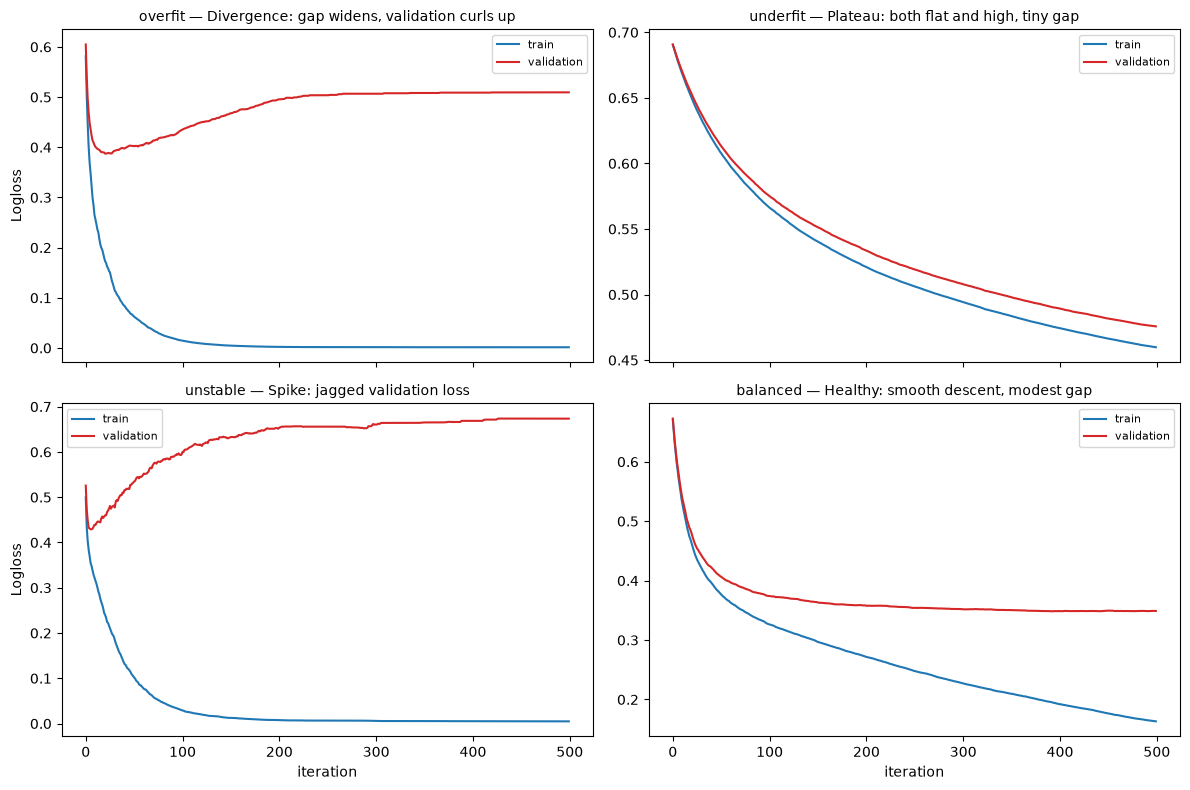

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
notes = {"overfit": "Divergence: gap widens, validation curls up",
         "underfit": "Plateau: both flat and high, tiny gap",
         "unstable": "Spike: jagged validation loss",
         "balanced": "Healthy: smooth descent, modest gap"}
for ax, (name, res) in zip(axes.ravel(), curves.items()):
    ax.plot(res["learn"]["Logloss"], label="train", color="tab:blue")
    ax.plot(res["validation"]["Logloss"], label="validation", color="tab:red")
    ax.set_title(f"{name} — {notes[name]}", fontsize=10)
    ax.legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("iteration")
for ax in axes[:, 0]:
    ax.set_ylabel("Logloss")
plt.tight_layout(); plt.show()

## 2. Diagnostic treatment candidates (§4.5.1)

| Observed symptom | Candidate interventions to validate |
|---|---|
| validation worsens while train improves | reduce depth, raise leaf regularization, reduce step size, or stop earlier |
| both curves remain high | add training budget, capacity, or features; relax excessive regularization |
| loss is jagged or spikes | reduce learning rate; inspect outliers, labels, and numerics |

No single curve shape identifies a cause. In particular, lowering learning rate can change both regularization and optimization; it does not merely delay an inevitable divergence. Change one factor, rerun on validation data, and report the result.

## 3. Quantifying the diagnosis

For the high-capacity candidate, compute the validation minimum and subsequent train improvement. These are descriptive landmarks, not proof of a universal pathology.

In [6]:
val_curve = np.array(curves["overfit"]["validation"]["Logloss"])
train_curve = np.array(curves["overfit"]["learn"]["Logloss"])

best_val_iter = int(val_curve.argmin())       # zero-based index
selected_trees = best_val_iter + 1            # CatBoost ntree_end is a tree count
train_improve = -np.diff(train_curve)
train_active = (int(np.max(np.where(train_improve > 1e-4)) + 1)
                if (train_improve > 1e-4).any() else len(train_curve))

print(f"validation-selected tree count: {selected_trees}")
print(f"training change above tolerance through index: {train_active}")
print("Later training improvement was not rewarded by this validation curve; "
      "that is a selection signal, not proof that every later tree memorizes.")

validation-selected tree count: 21
training change above tolerance through index: 157
Later training improvement was not rewarded by this validation curve; that is a selection signal, not proof that every later tree memorizes.


## 4. Freeze the validation-selected prefix and open test once

A final test set is not a second learning curve. Computing its staged optimum would tune on test repeatedly. We freeze `best_val_iter + 1` from validation, truncate a copy to exactly that many trees, and compute one test result.

In [7]:
import copy

m_over = models["overfit"]
m_selected = copy.deepcopy(m_over)
m_selected.shrink(ntree_end=selected_trees)

# One prediction from the frozen prefix; no staged test trajectory or test optimum.
test_proba = m_selected.predict_proba(X_te)[:, 1]
print({"validation_selected_trees": selected_trees,
       "retained_trees": m_selected.tree_count_,
       "one_shot_test_logloss": round(log_loss(y_te, test_proba), 4),
       "one_shot_test_auc": round(roc_auc_score(y_te, test_proba), 4)})
assert m_selected.tree_count_ == selected_trees

{'validation_selected_trees': 21, 'retained_trees': 21, 'one_shot_test_logloss': 0.3769, 'one_shot_test_auc': 0.9105}


## 5. Acting on a validation diagnosis with `shrink()`

`model.shrink(ntree_end=k)` retains the first `k` trees. Because `argmin` returns a zero-based index, retain `best_val_iter + 1`. Truncation recovers the validation-selected prefix; its test utility is empirical and must not be compared against multiple test prefixes.

In [8]:
print(f"Full development model trees: {m_over.tree_count_}")
print(f"Validation-selected prefix:    {m_selected.tree_count_}")
print("The final test result was computed once in the previous cell after this "
      "tree count was frozen.")

Full development model trees: 500
Validation-selected prefix:    21
The final test result was computed once in the previous cell after this tree count was frozen.


## 6. The metric curve is a second witness

Logloss and AUC can move differently because they measure different properties. Record both, but do not diagnose calibration from Logloss alone or prescribe post-hoc calibration merely because AUC is steadier. Calibration requires reliability/proper-score evidence on a dedicated split; ranking and probability quality can both be affected by model changes.

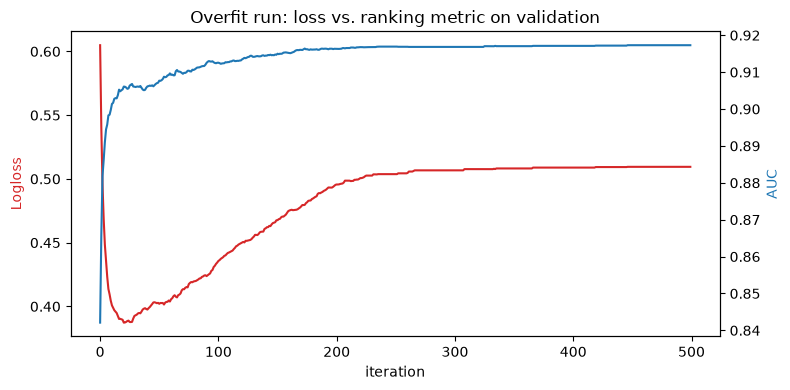

In [9]:
res_over = curves["overfit"]
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(res_over["validation"]["Logloss"], color="tab:red", label="valid Logloss")
ax1.set_ylabel("Logloss", color="tab:red"); ax1.set_xlabel("iteration")
ax2 = ax1.twinx()
ax2.plot(res_over["validation"]["AUC"], color="tab:blue", label="valid AUC")
ax2.set_ylabel("AUC", color="tab:blue")
plt.title("Overfit run: loss vs. ranking metric on validation")
plt.tight_layout(); plt.show()

## Takeaways

- Divergence, plateau, and spike are useful visual hypotheses, not uniquely identifying diagnoses.
- Compare train and validation paths, multiple metrics, and controlled interventions.
- Learning rate, depth, L2, and stopping interact; lowering learning rate need not merely delay the same outcome.
- `staged_predict_proba` evaluates staged ensembles on another dataset, but the test set remains one-shot evidence after choices are frozen.
- `shrink(ntree_end=k)` truncates a model. It can recover the validation-selected prefix; it does not supply free or guaranteed accuracy.

## Exercises

**Exercise 1.** Run the mystery configuration, plot curves, and report the observed silhouette and at least two plausible causes before choosing an intervention.

<details><summary>Solution</summary>

Compute the curves. If both still descend, additional budget is a candidate; if they flatten high, capacity/features/regularization are candidates. Validate the intervention.
</details>

**Exercise 2.** Compare higher L2 with half learning rate from the high-capacity candidate. Report validation minima and upturns; do not require either treatment to win or an upturn to persist.

<details><summary>Solution</summary>

```python
for name, p in [("higher L2", dict(depth=10, l2_leaf_reg=10, learning_rate=0.15)),
                ("smaller step", dict(depth=10, l2_leaf_reg=0.2, learning_rate=0.075))]:
    m = CatBoostClassifier(iterations=500, random_seed=RANDOM_SEED,
                           verbose=0, allow_writing_files=False, **p)
    m.fit(X_tr, y_tr, eval_set=(X_va, y_va))
    v = m.get_evals_result()["validation"]["Logloss"]
    print(name, min(v), int(np.argmin(v)))
```
</details>

**Exercise 3.** Repeat the reference candidate on 10%, 30%, and 100% of training rows. Report the gap and validation loss across resampled subsets.

<details><summary>Solution</summary>

More data can reduce estimator variance, but a single nested-prefix run can move non-monotonically and confound sample composition. Repeat subsets; the result does not establish that stochastic regularization has low value on all large datasets.
</details>